# Mini-Project: Bespoke Retrieval-Augmented Generation (RAG)


## Overview


In this project, you will build a hybrid system that combines three components into a single RAG-style pipeline:

- A **language model (GPT-2)** for text generation.
- A **Query-Key Memory Network (QK-MemNet)** for factual retrieval.
- A **router** that decides whether to use autoregressive generation or to invoke the retrieval model.

This assignment combines language modeling, retrieval, text classification, and data curation.

The overall goal is to build a system that generates biographies of real people. At each step of generation, a router model examines the current text that has been generated so far and decides: "Should we **generate** the next token with GPT-2, or **retrieve** a fact from structured memory?"

**Note:** This system is **not expected to produce perfect biographies**. GPT-2 is a small model and the QK-MemNet uses bag-of-words representations. The goal is to demonstrate the *architecture*, decision-making between retrieval and generation, and integration of symbolic memory with neural models.

## Learning objectives

The learning objective of this assignment is to provide practical experience handling structured and unstructured data, training classifiers on real-world data, and incorporating different models into a single, practical generative system.

We ask you to envision that you have been tasked with creating a specialized system that generates biographies for famous people that tamps down on hallucinations as much as possible. With the very powerful LLMs available today, retrieval-augmented generation (RAG) might be achieved by using web search to pull some web pages for a person and then concatenating the contents of the web page along with a prompt, and letting a very large LLM do its thing with attention. However, this is not very exciting as an assignment that combines skills across the entire class.

Instead, we are going to pretend that we have an LLM that has not been able to pre-train on biographies of famous people (if you want, you can pretend that we are working on a system that generates biographies of un-famous people). To simulate this setting, we will work with GPT-2 because it is less capable of memorizing facts. This also means we can work with language models that are small enough to not need a lot of computing resources. No one will realistically use GPT-2, but GPT-2 has not memorized a lot of biographical information, so it suits our purposes.

We will also need a retriever. For this assignment, we will build a Query-Key Memory Network (QK-MemNet), inspired by Key-Value Memory Networks (KV-MemNets). A Memory Network learns to index into a data source (external memory) using attention mechanisms. They were considered a promising pathway to more sophisticated retrieval and generation capabilities before the Transformer came along. A Query-Key Memory Network assumes that memory is structured as a hash table and learns the mapping from an arbitrary query to the appropriate keys in order to retrieve its associated values. Where a hash table requires an exact match between query and key, a QK-MemNet learns a function that maps queries to keys. Memory networks use attention in a way that somewhat corresponds to Transformers. This makes sense because Transformers use their K, V, and Q sub-networks that are inspired by hash tables. We thus get to play with something that shares a lot of commonalities with Transformers without implementing all the complexity of the Transformer (and for which the code is already given earlier in the lectures).

The QK-MemNet will store biographical facts (birthdates, birth places, etc.), but not full biographies. So we will have GPT-2 generate biographies, and it will likely hallucinate the facts. How do we know when to retrieve? For this, we will train a classifier that will tell us whether the next token(s) should be retrieved or if we should let GPT-2 generate the next tokens. Thus the generation flow looks like this:

```
GPT-2 generates token → Classifier checks: is a fact needed next?
                            ↳ YES → QK-MemNet retrieves fact → inject into context
                            ↳ NO  → continue generating
```

The router will be a fine-tuned version of BERT, trained to predict whether the next token(s) should be facts. To fine-tune BERT, we will need to construct a training set of sentence fragments, some of which are followed by facts and some of which are not. Thus, we will need to prepare a specialized dataset. We will provide you with the raw materials to do this.

There are other ways this RAG project might have been done. We might have let the LM generate and then tried to detect hallucinated facts and "rewind" and invoke the retriever. That has its own challenges. We might fine-tune the LM to generate placeholder text and then grab those placeholders and call the retriever when a placeholder appears. We have chosen to insist on a particular structure for the assignment that involves creating datasets, training a classifier, and building a bespoke model architecture from scratch for their educational value.

By the end of this project, you will have practiced:

1. Using open-weight language models.
2. Creating supervised learning datasets that align structured knowledge with unstructured text.
3. Training a neural binary classifier off annotated data.
4. Implementing attention-based neural architectures for retrieval.
5. Building specialized RAG systems.

## How to use this Notebook


- Cells marked with `### START CODE HERE ###` and `### END CODE HERE ###` are where you write your solutions.
- Do **not** modify provided helper functions or test cells unless instructed.
- Run cells **in order**, later parts depend on earlier results.

The project is split across three notebooks:

- **Part A: Router**
- **Part B: Memory Network**
- **Parts C–D: GPT-2 fine-tuning (optional) and RAG integration**

This notebook covers Part B. Complete Part A and save the annotation datasets before starting.


## Grading Summary: Part B

| Section | Title | Function(s) | Checks | Points |
| --- | --- | --- | --- | ---: |
| B.2 | Build QK-MemNet Training Data | `build_person_to_kv_map`, `build_qkmem_dataset` | 2.1–2.4 | 5 |
| B.3 | Implement the MemNet Architecture | `QKMemNet.__init__`, `QKMemNet.forward` | 3.1–3.3 | 5 |
| B.4.a | Write an evaluation function | `evaluate` | 4.1.1–4.1.3 | 5 |
| B.4.b | Write the training loop | `train_qkmem_model` | 4.2.1 | 5 |
| **Total** | | | | **20** |

The checks listed above are the tests used by the autograder. You can try them using the Student Self-check at the end of this notebook.


# Setting Up

In [ ]:
!pip install unidecode spacy --quiet

In [ ]:
import json
import re
import random
from pathlib import Path
from typing import Any, Dict, List, Tuple, Optional
from copy import deepcopy
import unidecode

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

In [ ]:
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {DEVICE}")

The following cell mounts Google Drive to the Colab environment so that files stored in Drive can be accessed directly from the notebook. This is only necessary if you are using Google Colab.

After mounting, we define the root directory of the project located in Google Drive. This provides a centralized path for all file references in the project.

In [ ]:
PROJECT_ROOT = Path("/content/drive/MyDrive/cs7650_final_project")  # adjust as needed

In [ ]:
MOUNT_GOOGLE_DRIVE = True

if MOUNT_GOOGLE_DRIVE:
  from google.colab import drive
  drive.mount("/content/drive", force_remount=False)

## A.1. Load the provided Wikidata and SimpleWiki bios (0 points)


Data is pulled directly from a database of US politician biography data hosted on Hugging Face Hub (https://huggingface.co/datasets/specialsaucem/us-politicians).


Each record combines two kinds of data: WikiData structured facts about an individual and biographical introductory text, pulled from Simplified Wikipedia or normal Wikipedia, or both.

We will only be using records with a `simple-bio` entry, which contains simplified natural language.

People are split into train/dev/test with a proportional 80/10/10 split
(shuffled with a fixed random seed for reproducibility).



The following cells create 3 variables:
- `db_clean_train` / `db_clean_dev` / `db_clean_test`: structured Wikidata
  facts per person, keyed by lowercase full name -- e.g.
  `db_clean_train["calvin coolidge"]["date of birth"]`. Multiple values for
  the same attribute are joined with `"; "`.

A handful of people share the same lowercase name (e.g. two different
"Henry Clay"s) -- the first one encountered is kept and the rest are
dropped and printed below. Don't worry about that.


In [ ]:
from huggingface_hub import hf_hub_download

HF_DATASET_REPO = "specialsaucem/us-politicians"  # https://huggingface.co/datasets/specialsaucem/us-politicians

people_jsonl_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename="people.jsonl",
    repo_type="dataset",
)

db_clean_all = {}
title_to_text_all = {}

with open(people_jsonl_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        rec = json.loads(line)

        simple_bio = rec.get("simple-bio")
        if not simple_bio:
            continue  # restrict to people with a Simple Wikipedia bio, same
                       # restriction the old full_properties_simple_bio.csv
                       # already applied.

        name_key = str(rec["name"]).strip().lower()

        if name_key in db_clean_all:
            continue

        db_clean_all[name_key] = rec["properties"]
        title_to_text_all[name_key] = simple_bio

print(f"\n{len(db_clean_all)} people total after deduplication.")

# Proportional 80/10/10 train/dev/test split, shuffled with a fixed seed
# (independent Random instance so this doesn't disturb the notebook's
# global `random` state, which was already seeded in the Setting Up section).
all_names = sorted(db_clean_all)
rng = random.Random(RANDOM_SEED)
rng.shuffle(all_names)

n_total = len(all_names)
n_train = round(n_total * 0.8)
n_dev = round(n_total * 0.1)

train_names = all_names[:n_train]
dev_names = all_names[n_train:n_train + n_dev]
test_names = all_names[n_train + n_dev:]

def _subset(d, names):
    return {n: d[n] for n in names}

db_clean_train = _subset(db_clean_all, train_names)
db_clean_dev = _subset(db_clean_all, dev_names)
db_clean_test = _subset(db_clean_all, test_names)

print(f"Split sizes: train={len(db_clean_train)}, dev={len(db_clean_dev)}, test={len(db_clean_test)}")


Print the split sizes and inspect one example from the train split.

In [ ]:
print(
    f"Split sizes: train={len(db_clean_train)}, dev={len(db_clean_dev)}, test={len(db_clean_test)}"
)

# Get the first biography name
example_name = 'lillian gordy carter'
print("One train example:")
print("Biography name:", example_name)
db_clean_all[example_name]


Build `title_to_text`, a lookup from each person's (lowercased) name to
their Simple Wikipedia biography text -- reusing the `simple-bio` values
already parsed from `people.jsonl` above, instead of downloading the old
Kaggle `simplenormal-wikipedia-sections` dataset. `people.jsonl` doesn't
carry a separate article title, so this is keyed the same way as
`db_clean_*` (lowercased full name).


In [ ]:
title_to_text = title_to_text_all
print("SimpleWiki bios loaded:", len(title_to_text))

Print one biography text example so you can see what the SimpleWiki input looks like.

In [ ]:
example_simplewiki_text = title_to_text[example_name]

print(f"SimpleWiki text example title: {example_name}")
print(example_simplewiki_text[:500])

# Section B: Query-Key Memory Network for Fact Retrieval (20 points)

In this assignment you will build a retriever. Specifically, it will be something called a **Query-Key Memory Network** (QK-MemNet). The QK-MemNet will take a natural language sentence (a query) and predict which key in a hash-table should be indexed. Our data will be stored in a `(relation, value)` format for each person and the natural language sentences will be fragments of biography.

The router should have already told us that the sentence fragment is a prefix to be followed by a fact. We now just need to use the QK-MemNet to retrieve the correct fact.

The project is inspired by Key-value memory networks are described in [Miller et al., 2016](https://arxiv.org/abs/1606.03126). The core idea of a KV-MemNet is to store knowledge as (key, value) pairs and use an attention mechanism over keys to retrieve the appropriate value. The key is designed to match the *question*, while the value is designed to match the *answer*.

The QK-MemNet will use an attention-like structure similar to the Q and K portions of a Transformer. However, we do not need the V because once we know the Q we can directly retrieve the data.

## B.0. Understand the Memory Network

We start with natural language, a prefix identified by the router to be succeeded by a fact. The prefix is converted into tokens. In the diagram I show a multihot bag-of-words. However an LSTM or other sequence-aware process could be used to embed.

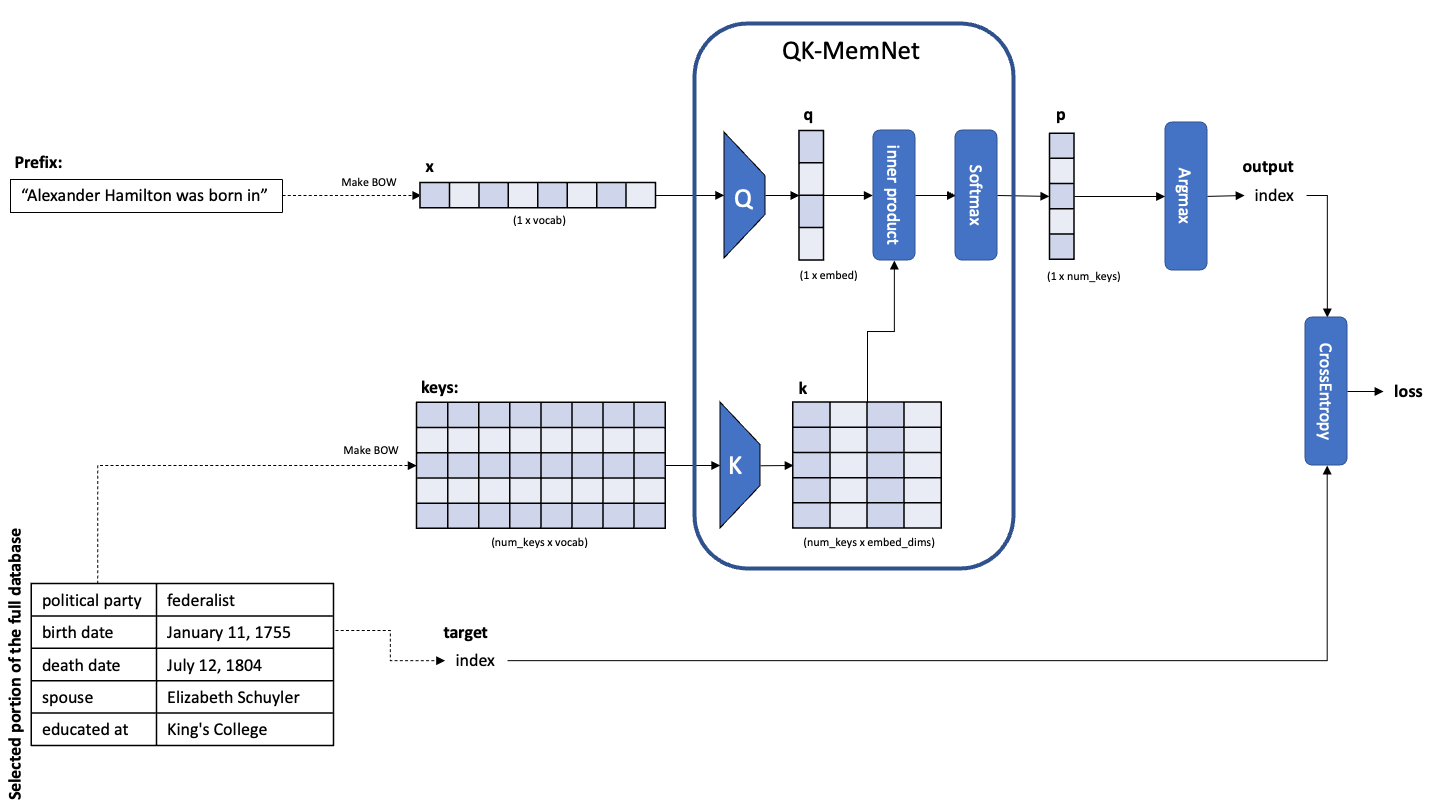

`Q` and `K` are linear layers that embed the prefix and each key in the data for the individual. The inner-product is the attention mechanism.

## B.1: Build the vocabulary (0 points)

The vocabulary covers all words that appear in DB keys, DB values, and the SimpleWiki biography texts for people in all three splits. This ensures that both queries (biography prefixes) and keys/values can be represented.

We will use spaCy to break the text into individual word units.

In [ ]:
SELECTED_RELATIONS = [
 'country of citizenship',
 'sex or gender',
 'occupation',
 'position held',
 'date of birth',
 'place of birth',
 'member of political party',
 'date of death',
 'educated at',
 'place of death',
 'residence',
 'spouse',
 'member of',
 'cause of death',
 'field of work',
]

In [ ]:
ANNOTATION_OUTPUT_DIR = PROJECT_ROOT / "annotation"
ANNOTATION_TRAIN_PATH = ANNOTATION_OUTPUT_DIR / "annotation_train_records.json"
ANNOTATION_DEV_PATH = ANNOTATION_OUTPUT_DIR / "annotation_dev_records.json"
ANNOTATION_TEST_PATH = ANNOTATION_OUTPUT_DIR / "annotation_test_records.json"

def read_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))

def write_json(obj: Any, path: Path):
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")

annotation_train_records = read_json(ANNOTATION_TRAIN_PATH)
annotation_dev_records = read_json(ANNOTATION_DEV_PATH)
annotation_test_records = read_json(ANNOTATION_TEST_PATH)
annotation_all_records = annotation_train_records + annotation_dev_records + annotation_test_records

In [ ]:
import spacy
nlp = spacy.blank("en")

def tokenize(text: str) -> List[str]:
    doc = nlp.make_doc(text.replace('_', ' '))
    return [unidecode.unidecode(tok.text.lower()) for tok in doc]

The vocabulary object:

In [ ]:
class Vocab:
    def __init__(self):
        self._word2index = {}
        self._index2word = {}
        self._n_words = 0

    def num_words(self) -> int:
        return self._n_words

    def word2index(self, word: str) -> int:
        return self._word2index.get(word, -1)

    def index2word(self, idx: int) -> str:
        return self._index2word[idx]

    def add_word(self, word: str):
        if word not in self._word2index:
            self._word2index[word] = self._n_words
            self._index2word[self._n_words] = word
            self._n_words += 1

    def add_text(self, text: str):
        for token in tokenize(text):
            self.add_word(token)

    def __contains__(self, word: str) -> bool:
        return word in self._word2index

    def to_dict(self) -> dict:
        return dict(self._word2index)

    @classmethod
    def from_dict(cls, word2index: dict) -> "Vocab":
        vocab = cls()
        for word, idx in sorted(word2index.items(), key=lambda kv: kv[1]):
            vocab._word2index[word] = idx
            vocab._index2word[idx] = word
        vocab._n_words = len(vocab._word2index)
        return vocab

Build the vocabulary

In [ ]:
def build_vocab(db_all, records_all):
  vocab = Vocab()
  for name, entry in tqdm(db_all.items(), desc="Building vocab from DB"):
    vocab.add_text(name)
    for rel in SELECTED_RELATIONS:
      if rel in entry:
        vocab.add_text(rel)
        for val in entry[rel].split(";"):
          vocab.add_text(val.strip())
  for record in tqdm(records_all, desc="Building vocab from records"):
    vocab.add_text(record['text'])
  return vocab

VOCAB = build_vocab(db_clean_all, annotation_all_records)
vocab_file_path = PROJECT_ROOT / "vocab.json"
vocab_file_path.parent.mkdir(parents=True, exist_ok=True)
write_json(VOCAB.to_dict(), vocab_file_path)
print(f"Vocabulary size: {VOCAB.num_words()}")

## B.2: Build QK-MemNet Training Data (5 points)



In this step, we will create two data structures.

The first is `person_to_kv`, a mapping from person names to key-value data. The examples below use fictional people and facts:
```python
{'alex example': [('date of birth', '12 March 1980'),
                  ('occupation', 'teacher'),
                  ('place of birth', 'Maple Town')],
 'sam sample': [('date of birth', '8 June 1990'),
                ('occupation', 'engineer'),
                ('place of birth', 'Cedar Town')]}
```
This data structure is used to zero in on only the key-value data for a specific person. In essence, each person has their own knowledgebase.

The second is the QK-MemNet training dataset, in the form of a list of dictionaries containing:
- `query`: the biography prefix, copied from the record's `text`.
- `name`: who the query is about.
- `kv_pairs`: list of `(relation, value)` pairs for that person (from `person_to_kv`).
- `target_value`: the specific value that should be retrieved.
- `target_relation`: the relation that was matched.
- `target_idx`: the zero-based index of the matching `(relation, value)` pair in `kv_pairs`.

**Where do queries come from?**

We reuse the same annotation logic from the classifier notebook. We scan the SimpleWiki biography, and when a token matches a word from the person's fact box, the prefix up to that point becomes a query. The key difference from the classifier notebook is that we also record **which relation** was matched, so we know which key-value pair is the correct retrieval target.

Before calling `build_qkmem_dataset`, each positive record must contain `name`, `text`, `label`, `relation`, and `value`, as shown below.

```python
{
    "name": "alex example",
    "text": "Alex Example was born on",
    "label": 1,
    "relation": "date of birth",
    "value": "12 March 1980",
}
```

We only include positive records (`label == 1`). Using the memory above, the record produces:

```python
{
    "name": "alex example",
    "query": "Alex Example was born on",
    "kv_pairs": [("date of birth", "12 March 1980"),
                 ("occupation", "teacher"),
                 ("place of birth", "Maple Town")],
    "target_value": "12 March 1980",
    "target_relation": "date of birth",
    "target_idx": 0,
}
```

Use the relation names as they appear in the data (e.g., `date of birth`, not `date_of_birth`). The target pair must be present in that person's memory.

**Handling semicolons in values**

Some DB values contain multiple entries separated by semicolons (e.g., `position held: "President ; Senator"`). When building the key-value memory, we split these into **separate (key, value) pairs** — so `position held` with two values becomes two memory slots, both with the same key `"position held"` but different values `"President"` and `"Senator"`.

**Hint:** You might have already done a lot of the work needed when you created the router training data.

In [ ]:
def build_person_to_kv_map(db_split, selected_relations = SELECTED_RELATIONS):
  person_to_kv = {}
  ### START CODE HERE ###









  ### END CODE HERE ###
  return person_to_kv

In [ ]:
def build_qkmem_dataset(records_split, person_to_kv_split):
  dataset = []
  ### START CODE HERE ###









  ### END CODE HERE ###
  return dataset

In [ ]:
person_to_kv_train = build_person_to_kv_map(db_clean_train)
person_to_kv_dev = build_person_to_kv_map(db_clean_dev)
person_to_kv_test = build_person_to_kv_map(db_clean_test)
person_to_kv_all = person_to_kv_train | person_to_kv_dev | person_to_kv_test

# Save person_to_kv_all for use in part C.
PERSON_KV_ALL_PATH = ANNOTATION_OUTPUT_DIR / "person_to_kv_all.json"
write_json(person_to_kv_all, PERSON_KV_ALL_PATH)

qkmem_train = build_qkmem_dataset(annotation_train_records, person_to_kv_train)
qkmem_dev = build_qkmem_dataset(annotation_dev_records, person_to_kv_dev)
qkmem_test = build_qkmem_dataset(annotation_test_records, person_to_kv_test)

In [ ]:
print(f"QK-MemNet examples: train={len(qkmem_train):,}, dev={len(qkmem_dev):,}, test={len(qkmem_test):,}")
for ex in qkmem_train[0:10]:
    print(f"  Query:  {ex['query']}")
    print(f"  Target: {ex['target_relation']} → {ex['target_value']}")
    print(f"  KV pairs: {len(ex['kv_pairs'])}, target_idx: {ex['target_idx']}")
    print()

## B.3: Implement the MemNet Architecture (5 points)


Implement the Query-Key Memory Network.

In [ ]:
class QKMemNet(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int):
        """
        Arguments:
        vocab_size -- size of the bag-of-words vocabulary
        embed_dim -- dimension of the dense embedding space

        Create two linear layers:
        - self.Q: Linear(vocab_size, embed_dim) -- query embedding
        - self.K: Linear(vocab_size, embed_dim) -- key embedding
        """
        super(QKMemNet, self).__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim

        ### START CODE HERE ###









        ### END CODE HERE ###

    def forward(self, x: Any, keys: Any) -> torch.Tensor:
        """
        x: query BOW vector, shape (vocab_size,)
        keys: key BOW vectors, shape (num_keys, vocab_size)
        Returns: softmax attention probabilities, shape (num_keys,)
        """

        ### START CODE HERE ###









        ### END CODE HERE ###

        return p

In [ ]:
# Shape test
test_vocab_size = 100
test_embed_dim = 32
test_kv_pairs_size = 5
test_model = QKMemNet(vocab_size=test_vocab_size, embed_dim=test_embed_dim)
test_q = torch.randn(test_vocab_size)
test_k = torch.randn(test_kv_pairs_size, test_vocab_size)
test_attention = test_model(test_q, test_k)

assert test_attention.shape == (test_kv_pairs_size,), f"Expected shape ({test_kv_pairs_size},), got {test_attention.shape}"
print("Shape test passed.")

# Verify Q and K layer attributes and dimensions
assert hasattr(test_model, 'Q'), "Model must have attribute 'Q'"
assert hasattr(test_model, 'K'), "Model must have attribute 'K'"
assert isinstance(test_model.K, nn.Linear), "K must be nn.Linear"
assert isinstance(test_model.Q, nn.Linear), "Q must be nn.Linear"
assert test_model.Q.in_features == 100, "Q input must be vocab_size"
assert test_model.K.out_features == 32, "K output must be embed_dim"
print("Architecture test passed.")

In [ ]:
from torch import optim
import matplotlib.pyplot as plt

## B.4: Train the MemNet (10 points)

Now train the Memory Network on the real biography data from B.2.

**Suggested performance targets:**
- Training accuracy should reach **>80%** within a few epochs
- Dev accuracy should be **>70%**


In [ ]:
MEMNET_OUTPUT_DIR = Path(PROJECT_ROOT) / "models" / f"memnet"
MEMNET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

### B.4.a: Write an evaluation function (5 points)

This function will evaluate the model on a dataset---either the test set for final evaluation, or the development set for periodic checks on training.

The function should return the overall accuracy as well as the accuracy per relation type in the form of a hash, e.g., `{'date of birth': 0.66, 'place of birth': 0.75, ...}`. Return these as `(overall_acc, per_rel_acc)`. A prediction is correct when the index with the highest probability matches `target_idx`.

In [ ]:
from collections import Counter
def evaluate(model, dataset, vocab):
    model.eval()
    ### START CODE HERE ###









    ### END CODE HERE ###
    overall_acc = correct / total if total > 0 else 0.0
    per_rel_acc = {}
    for rel in per_rel_total:
        per_rel_acc[rel] = per_rel_correct[rel] / per_rel_total[rel]

    return overall_acc, per_rel_acc


### B.4.b: Write the training loop (5 points)

Train for enough epochs to see the loss converge. Evaluate on `qkmem_dev` periodically.

Return the trained model, a list of training losses per epoch, and a list of dev accuracies per epoch.


In [ ]:
def train_qkmem_model(model, train_data, dev_data, vocab, epochs, lr=0.001):
  epoch_losses = [] # Record loss values per epoch for plotting
  epoch_dev_accuracies = [] # record dev accuracy per epoch for plotting
  ### START CODE HERE ###









  ### END CODE HERE ###
  return model, epoch_losses, epoch_dev_accuracies

In [ ]:
EMBED_DIM = 128 # YOU CAN CHANGE THIS

qkmem_model = QKMemNet(VOCAB.num_words(), EMBED_DIM).to(DEVICE)

print(f"Model created: vocab_size={VOCAB.num_words()}, embed_dim={EMBED_DIM}")

In [ ]:
num_epochs = 5 # you can change this
learning_rate = 0.001 # you can change this

In [ ]:
TRAIN_MEM_NET = True

if TRAIN_MEM_NET:
  qkmem_model, losses, dev_accuracies = train_qkmem_model(qkmem_model,
                                                          train_data=qkmem_train,
                                                          dev_data=qkmem_dev,
                                                          vocab=VOCAB,
                                                          epochs=num_epochs,
                                                          lr=learning_rate)

  # Plot loss and dev accuracy
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
  ax1.plot(losses)
  ax1.set_xlabel("Epoch")
  ax1.set_ylabel("Loss")
  ax1.set_title("Training Loss")

  ax2.plot(dev_accuracies)
  ax2.set_xlabel("Epoch")
  ax2.set_ylabel("Accuracy")
  ax2.set_title("Dev Accuracy")
  plt.tight_layout()
  plt.show()
  print(f"Saving to {MEMNET_OUTPUT_DIR}")
  torch.save(qkmem_model, MEMNET_OUTPUT_DIR / "qkmemnet.pt")
else:
  qkmem_model = torch.load(MEMNET_OUTPUT_DIR / "qkmemnet.pt", weights_only=False)
  qkmem_model.to(DEVICE)

## B.5: Evaluate on Test Data (0 points)

Run evaluation on the held-out test set and report accuracy overall and per-relation.

In [ ]:
test_acc, test_per_rel = evaluate(qkmem_model, qkmem_test, VOCAB)
print(f"Test accuracy: {test_acc:.3f}")
print("\nPer-relation accuracy:")
for rel in sorted(test_per_rel, key=test_per_rel.get, reverse=True):
    print(f"  {rel}: {test_per_rel[rel]:.3f}")

In [ ]:
vocab_file_path = PROJECT_ROOT / "vocab.json"
vocab_file_path.parent.mkdir(parents=True, exist_ok=True)
write_json(VOCAB.to_dict(), vocab_file_path)
print(f"VOCAB successfully saved to {vocab_file_path}")

### Student Self-check/local-autograder:

Put `test_part_B.py` in your working directory and run the cell below. These checks match the autograder.


In [ ]:
from test_part_B import run_all

run_all(build_person_to_kv_map, build_qkmem_dataset, QKMemNet,
            evaluate, train_qkmem_model, Vocab)

Submit your completed `.ipynb` file to **HW5 Part B** on Gradescope.
